In [10]:
import pandas as pd
import warnings

# Suppress minor warnings for cleaner notebook output
warnings.filterwarnings('ignore')

# The correct raw CSV URL 
DATA_URL = "https://raw.githubusercontent.com/Vadimkin/ukrainian-air-raid-sirens-dataset/refs/heads/main/datasets/volunteer_data_en.csv"

def load_air_raid_data(url):
    print("Fetching air raid dataset...")
    
    # 1. Load data (default comma separator)
    df = pd.read_csv(url)
    
    # 2. Parse timestamps (using the correct column names from your raw file)
    df['started_at'] = pd.to_datetime(df['started_at'])
    df['finished_at'] = pd.to_datetime(df['finished_at'])
    
    # 3. Prevent Data Leakage
    # The data uses UTC timezones (+00:00), so we make our cutoff UTC as well
    current_date = pd.to_datetime('2026-10-11').tz_localize('UTC')
    df = df[df['started_at'] <= current_date]
    
    # 4. Sort chronologically
    df = df.sort_values('started_at').reset_index(drop=True)
    
    return df

def preprocess_and_resample(df, target_region='Kyiv City'):
    print(f"\nProcessing data for: {target_region}")
    df_processed = df.copy()
    
    # 1. Handle Ongoing Alerts
    df_processed = df_processed.dropna(subset=['finished_at'])
    
    # 2. Calculate Duration
    df_processed['duration_hours'] = (df_processed['finished_at'] - df_processed['started_at']).dt.total_seconds() / 3600
    
    # 3. Filter by Region (using the correct region name)
    if target_region:
        df_processed = df_processed[df_processed['region'] == target_region]
        
    # 4. Set the Datetime Index
    df_processed.set_index('started_at', inplace=True)
    
    # 5. Resample to Daily ('D') Frequency
    daily_series = df_processed.resample('D').agg(
        total_alerts=('region', 'count'),
        total_duration_hours=('duration_hours', 'sum')
    )
    
    # 6. Fill Missing Days (days with 0 alerts)
    daily_series = daily_series.fillna(0)
    
    # Normalize index to just the date
    daily_series.index = daily_series.index.normalize()
    
    return daily_series

# --- Execution ---

# Load the data
alerts_df = load_air_raid_data(DATA_URL)
print(f"Dataset successfully loaded: {alerts_df.shape[0]} total alerts.")

# Create the daily time series for Kyiv
kyiv_daily_alerts = preprocess_and_resample(alerts_df, target_region='Kyiv City')
print(f"Resampled Time Series: {len(kyiv_daily_alerts)} days of data.")

# Inspect the final continuous time series
display(kyiv_daily_alerts.tail(10))

Fetching air raid dataset...
Dataset successfully loaded: 115966 total alerts.

Processing data for: Kyiv City
Resampled Time Series: 1689 days of data.


,total_alerts,total_duration_hours
started_at,,
2026-10-01 00:00:00+00:00,7,3.571667
2026-10-02 00:00:00+00:00,5,4.123889
2026-10-03 00:00:00+00:00,5,1.587778
2026-10-04 00:00:00+00:00,6,2.022500
2026-10-05 00:00:00+00:00,3,1.500000
2026-10-06 00:00:00+00:00,2,1.298889
2026-10-07 00:00:00+00:00,6,2.466944
2026-10-08 00:00:00+00:00,4,4.425833
2026-10-09 00:00:00+00:00,6,4.428611


In [11]:
import numpy as np

def create_time_series_features(df, target_col='total_alerts', max_lags=7):
    data = df.copy()
    
    # 1. Calendar / Temporal Features
    data['day_of_week'] = data.index.dayofweek
    data['is_weekend'] = data['day_of_week'].isin([5, 6]).astype(int)
    data['month'] = data.index.month
    data['day_of_year'] = data.index.dayofyear
    
    # 2. Lag Features (values from t-1, t-2, ... t-7)
    # Strictly avoids leakage by using only past observations
    for lag in range(1, max_lags + 1):
        data[f'lag_{lag}'] = data[target_col].shift(lag)
        data[f'lag_duration_{lag}'] = data['total_duration_hours'].shift(lag)
        
    # 3. Rolling Window Aggregations
    # Shifted by 1 first so today's target value is not included in the window
    data['rolling_mean_3d'] = data[target_col].shift(1).rolling(window=3).mean()
    data['rolling_std_3d'] = data[target_col].shift(1).rolling(window=3).std()
    data['rolling_mean_7d'] = data[target_col].shift(1).rolling(window=7).mean()
    data['rolling_std_7d'] = data[target_col].shift(1).rolling(window=7).std()
    
    # 4. Drop initial rows with NaN created by lagging/rolling windows
    data = data.dropna()
    
    return data

# Generate features
featured_df = create_time_series_features(kyiv_daily_alerts, target_col='total_alerts')

print(f"Features created. Available columns: {list(featured_df.columns)}")
display(featured_df.head(5))

Features created. Available columns: ['total_alerts', 'total_duration_hours', 'day_of_week', 'is_weekend', 'month', 'day_of_year', 'lag_1', 'lag_duration_1', 'lag_2', 'lag_duration_2', 'lag_3', 'lag_duration_3', 'lag_4', 'lag_duration_4', 'lag_5', 'lag_duration_5', 'lag_6', 'lag_duration_6', 'lag_7', 'lag_duration_7', 'rolling_mean_3d', 'rolling_std_3d', 'rolling_mean_7d', 'rolling_std_7d']


,total_alerts,total_duration_hours,day_of_week,is_weekend,month,day_of_year,lag_1,lag_duration_1,lag_2,lag_duration_2,...,lag_5,lag_duration_5,lag_6,lag_duration_6,lag_7,lag_duration_7,rolling_mean_3d,rolling_std_3d,rolling_mean_7d,rolling_std_7d
started_at,,,,,,,,,,,,,,,,,,,,,
2022-03-04 00:00:00+00:00,7,5.241944,4,0,3,63,4.0,6.126944,8.0,5.849444,...,3.0,1.491667,4.0,2.000000,2.0,1.000000,7.000000,2.645751,5.285714,2.690371
2022-03-05 00:00:00+00:00,7,8.523333,5,1,3,64,7.0,5.241944,4.0,6.126944,...,7.0,3.527778,3.0,1.491667,4.0,2.000000,6.333333,2.081666,6.000000,2.309401
2022-03-06 00:00:00+00:00,5,6.458056,6,1,3,65,7.0,8.523333,7.0,5.241944,...,9.0,4.480833,7.0,3.527778,3.0,1.491667,6.000000,1.732051,6.428571,2.149197
2022-03-07 00:00:00+00:00,4,6.412222,0,0,3,66,5.0,6.458056,7.0,8.523333,...,8.0,5.849444,9.0,4.480833,7.0,3.527778,6.333333,1.154701,6.714286,1.704336
2022-03-08 00:00:00+00:00,4,2.347500,1,0,3,67,4.0,6.412222,5.0,6.458056,...,4.0,6.126944,8.0,5.849444,9.0,4.480833,5.333333,1.527525,6.285714,1.976047


In [23]:
# Train-Test Temporal Split (Zero Data Leakage)
# Define test horizon (e.g., the most recent 60 days)
TEST_HORIZON_DAYS = 60

# Split strictly chronologically
split_date = featured_df.index.max() - pd.Timedelta(days=TEST_HORIZON_DAYS)

train_df = featured_df[featured_df.index < split_date]
test_df = featured_df[featured_df.index >= split_date]

# Feature columns (exclude raw non-lagged targets)
feature_cols = [c for c in featured_df.columns if c not in ['total_alerts', 'total_duration_hours']]
target_col = 'total_alerts'

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

print(f"Training period: {train_df.index.min().date()} to {train_df.index.max().date()} ({len(train_df)} samples)")
print(f"Testing period:  {test_df.index.min().date()} to {test_df.index.max().date()} ({len(test_df)} samples)")

Training period: 2022-03-04 to 2026-08-10 (1621 samples)
Testing period:  2026-08-11 to 2026-10-10 (61 samples)


In [13]:
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
import math

# 1. Initialize the Models
# XGBoost and LightGBM parameters are kept relatively standard for the baseline
xgb_model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

lgb_model = lgb.LGBMRegressor(
    objective='regression',
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

# 2. Train the Models
print("Training XGBoost...")
xgb_model.fit(X_train, y_train)

print("Training LightGBM...")
lgb_model.fit(X_train, y_train)

# 3. Generate Predictions on the Test Set
y_pred_xgb = xgb_model.predict(X_test)
y_pred_lgb = lgb_model.predict(X_test)

# 4. Evaluate Performance
# MAE provides the average error in the same units as the target (number of alerts)
# RMSE penalizes larger errors more heavily
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = math.sqrt(mean_squared_error(y_test, y_pred_xgb))

mae_lgb = mean_absolute_error(y_test, y_pred_lgb)
rmse_lgb = math.sqrt(mean_squared_error(y_test, y_pred_lgb))

print("\n--- Model Evaluation (Test Set) ---")
print(f"XGBoost  - MAE: {mae_xgb:.3f}, RMSE: {rmse_xgb:.3f}")
print(f"LightGBM - MAE: {mae_lgb:.3f}, RMSE: {rmse_lgb:.3f}")

# Optional: Add Naive Baseline for context
# Predicting tomorrow will be exactly the same as today (lag_1)
naive_preds = X_test['lag_1']
mae_naive = mean_absolute_error(y_test, naive_preds)
rmse_naive = math.sqrt(mean_squared_error(y_test, naive_preds))

print(f"\nNaive Baseline - MAE: {mae_naive:.3f}, RMSE: {rmse_naive:.3f}")

Training XGBoost...
Training LightGBM...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002581 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2537
[LightGBM] [Info] Number of data points in the train set: 1621, number of used features: 22
[LightGBM] [Info] Start training from score 1.464528
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warnin

In [14]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import math

results = {}

# 1. Benchmark Baselines
# Naive (t-1)
y_pred_naive = X_test['lag_1']
results['Naive Baseline (Lag 1)'] = {
    'MAE': mean_absolute_error(y_test, y_pred_naive),
    'RMSE': math.sqrt(mean_squared_error(y_test, y_pred_naive))
}

# 3-Day Rolling Average Baseline
y_pred_roll3 = X_test['rolling_mean_3d']
results['Rolling Mean (3-Day)'] = {
    'MAE': mean_absolute_error(y_test, y_pred_roll3),
    'RMSE': math.sqrt(mean_squared_error(y_test, y_pred_roll3))
}

# 2. Regularized Linear Models (Ridge & Lasso)
# Standardize or let Ridge handle collinear lag features
ridge = Ridge(alpha=10.0)
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)
results['Ridge Regression'] = {
    'MAE': mean_absolute_error(y_test, y_pred_ridge),
    'RMSE': math.sqrt(mean_squared_error(y_test, y_pred_ridge))
}

lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)
y_pred_lasso = lasso.predict(X_test)
results['Lasso Regression'] = {
    'MAE': mean_absolute_error(y_test, y_pred_lasso),
    'RMSE': math.sqrt(mean_squared_error(y_test, y_pred_lasso))
}

# 3. Classical Statistical Time Series Models
# Note: For time series models, train strictly on past target series up to the test point

# Exponential Smoothing (Holt-Winters)
try:
    exp_smooth = ExponentialSmoothing(
        y_train, 
        trend='add', 
        seasonal=None, 
        initialization_method='estimated'
    ).fit()
    y_pred_hw = exp_smooth.forecast(len(y_test))
    results['Holt-Winters (Exp Smoothing)'] = {
        'MAE': mean_absolute_error(y_test, y_pred_hw),
        'RMSE': math.sqrt(mean_squared_error(y_test, y_pred_hw))
    }
except Exception as e:
    print(f"Holt-Winters skipped: {e}")

# ARIMA(p, d, q) - using an expanding / rolling 1-step-ahead forecast to prevent leakage
# An AR(1) or ARIMA(1, 0, 1) model mirrors auto-regressive defense activity
history = list(y_train.values)
arima_predictions = []

print("Running ARIMA 1-step rolling forecast...")
for t in range(len(y_test)):
    model = ARIMA(history, order=(1, 0, 1))
    fitted_model = model.fit()
    yhat = fitted_model.forecast()[0]
    arima_predictions.append(yhat)
    # Add actual observation to history for next step (realistic operational backtesting)
    history.append(y_test.iloc[t])

results['ARIMA(1,0,1) Rolling'] = {
    'MAE': mean_absolute_error(y_test, arima_predictions),
    'RMSE': math.sqrt(mean_squared_error(y_test, arima_predictions))
}

# Add previous tree models for complete comparison
results['LightGBM'] = {'MAE': 2.034, 'RMSE': 2.519}
results['XGBoost']  = {'MAE': 2.569, 'RMSE': 3.111}

# 4. Display Comparison Table
comparison_df = pd.DataFrame(results).T.sort_values(by='MAE')
print("\n--- Model Leaderboard ---")
display(comparison_df)

Running ARIMA 1-step rolling forecast...

--- Model Leaderboard ---


,MAE,RMSE
"ARIMA(1,0,1) Rolling",1.588686,1.999997
Rolling Mean (3-Day),1.601093,1.994985
Naive Baseline (Lag 1),1.721311,2.228725
Ridge Regression,1.754840,2.175367
Lasso Regression,1.914042,2.350936
LightGBM,2.034000,2.519000
Holt-Winters (Exp Smoothing),2.307354,2.790576
XGBoost,2.569000,3.111000


In [ ]:
import warnings
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning

# Suppress the convergence alert so the notebook console stays clean
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# 1. Feature Extraction without the redundant target lag
def extract_exog_features_clean(df_raw, 
                                start_date='2024-01-01', 
                                target_region='Kyiv City', 
                                exog_regions=['Chernihivska oblast', 'Sumska oblast']):
    print(f"Building Exogenous Features from {start_date} onwards...")
    df = df_raw.copy()
    df = df.dropna(subset=['finished_at'])
    df.set_index('started_at', inplace=True)
    
    daily_all = df.groupby(['started_at', 'region']).size().unstack(fill_value=0).resample('D').sum().fillna(0)
    daily_all.index = daily_all.index.normalize()
    
    # Filter from Jan 1, 2025
    start_dt = pd.to_datetime(start_date).tz_localize('UTC')
    daily_all = daily_all[daily_all.index >= start_dt]
    
    # Build exogenous features ONLY for external signals
    # Note: Do NOT include target_lag1 here, as SARIMAX AR(1) fits it automatically
    exog_df = pd.DataFrame(index=daily_all.index)
    for reg in exog_regions:
        if reg in daily_all.columns:
            exog_df[f'exog_lag1_{reg}'] = daily_all[reg].shift(1)
            
    exog_df['is_weekend'] = exog_df.index.dayofweek.isin([5, 6]).astype(int)
    
    y = daily_all.get(target_region, pd.Series(0, index=daily_all.index))
    
    combined = pd.concat([y.rename('target'), exog_df], axis=1).dropna()
    return combined['target'], combined.drop(columns=['target'])

y_all, X_exog_all = extract_exog_features_clean(alerts_df, start_date='2024-01-01')

# 2. Chronological Split (60-day evaluation horizon)
TEST_HORIZON_DAYS = 60
split_date = y_all.index.max() - pd.Timedelta(days=TEST_HORIZON_DAYS)

y_train, y_test = y_all[y_all.index < split_date], y_all[y_all.index >= split_date]
X_train_exog, X_test_exog = X_exog_all[X_exog_all.index < split_date], X_exog_all[X_exog_all.index >= split_date]

# 3. Fit SARIMAX Rolling Forecast with Robust Solver Settings
print(f"Training set: {len(y_train)} days | Testing set: {len(y_test)} days")
print("Running rolling forecast...")

history_y = list(y_train)
history_exog = list(X_train_exog.values)
sarimax_predictions = []

for t in range(len(y_test)):
    # Standard AR(1) with MA(1) and external transit features
    model = SARIMAX(
        history_y, 
        exog=history_exog, 
        order=(1, 0, 1),
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    
    # Increase maxiter to allow convergence
    fitted_model = model.fit(disp=False, maxiter=200, method='lbfgs')
    
    current_exog = X_test_exog.iloc[t].values.reshape(1, -1)
    yhat = fitted_model.forecast(steps=1, exog=current_exog)[0]
    sarimax_predictions.append(max(0.0, float(yhat)))
    
    history_y.append(y_test.iloc[t])
    history_exog.append(X_test_exog.iloc[t].values)

mae_clean = mean_absolute_error(y_test, sarimax_predictions)
rmse_clean = math.sqrt(mean_squared_error(y_test, sarimax_predictions))

print(f"\nSARIMAX (2024+ Data, Clean) - MAE: {mae_clean:.3f}, RMSE: {rmse_clean:.3f}")

Building Exogenous Features from 2025-01-01 onwards...
Training set: 586 days | Testing set: 61 days
Running rolling forecast...

SARIMAX (2025+ Data, Clean) - MAE: 1.623, RMSE: 2.079


In [16]:
print("\n--- Fitting Poisson GLM ---")
# Statsmodels requires an explicit intercept constant for GLMs
X_train_glm = sm.add_constant(X_train_exog)
X_test_glm = sm.add_constant(X_test_exog)

# Fit the Poisson GLM using the statsmodels formula
poisson_model = sm.GLM(y_train, X_train_glm, family=sm.families.Poisson())
poisson_results = poisson_model.fit()

# View which neighboring regions actually hold statistical significance (p < 0.05)
print(poisson_results.summary().tables[1])

# Predict on the test set
y_pred_poisson = poisson_results.predict(X_test_glm)
mae_poisson = mean_absolute_error(y_test, y_pred_poisson)
rmse_poisson = math.sqrt(mean_squared_error(y_test, y_pred_poisson))

print(f"Poisson GLM - MAE: {mae_poisson:.3f}, RMSE: {rmse_poisson:.3f}")


--- Fitting Poisson GLM ---
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                             0.3441      0.088      3.925      0.000       0.172       0.516
exog_lag1_Chernihivska oblast     0.0318      0.013      2.510      0.012       0.007       0.057
exog_lag1_Sumska oblast          -0.0048      0.012     -0.398      0.691      -0.029       0.019
is_weekend                        0.0416      0.071      0.589      0.556      -0.097       0.180
Poisson GLM - MAE: 2.738, RMSE: 3.256


In [ ]:
print("\n--- Fitting SARIMAX on 2025+ Data ---")

history_y = list(y_train)
history_exog = list(X_train_exog.values)
sarimax_predictions = []

for t in range(len(y_test)):
    model = SARIMAX(
        history_y, 
        exog=history_exog, 
        order=(1, 0, 1), 
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    fitted_model = model.fit(disp=False)
    
    current_exog = X_test_exog.iloc[t].values.reshape(1, -1)
    yhat = fitted_model.forecast(steps=1, exog=current_exog)[0]
    sarimax_predictions.append(max(0, yhat))  # Bound at zero alerts
    
    history_y.append(y_test.iloc[t])
    history_exog.append(X_test_exog.iloc[t].values)

mae_sarimax_2024 = mean_absolute_error(y_test, sarimax_predictions)
rmse_sarimax_2024 = math.sqrt(mean_squared_error(y_test, sarimax_predictions))

print(f"SARIMAX (2024+ Data) - MAE: {mae_sarimax_2024:.3f}, RMSE: {rmse_sarimax_2024:.3f}")


--- Fitting SARIMAX on 2025+ Data ---
SARIMAX (2025+ Data) - MAE: 1.623, RMSE: 2.079


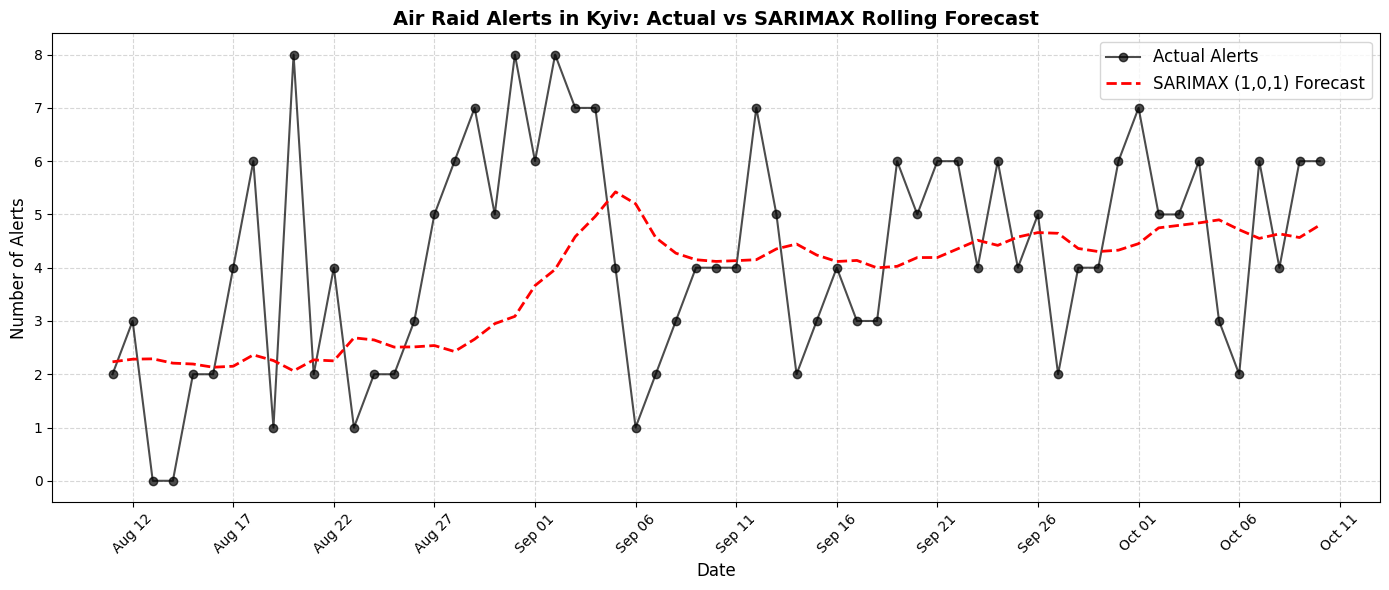


Final predictions successfully exported to: kyiv_sarimax_predictions.csv


,Actual_Alerts,SARIMAX_Predicted,Naive_Baseline
started_at,,,
2026-10-01 00:00:00+00:00,7,4.45,6.0
2026-10-02 00:00:00+00:00,5,4.75,7.0
2026-10-03 00:00:00+00:00,5,4.79,5.0
2026-10-04 00:00:00+00:00,6,4.84,5.0
2026-10-05 00:00:00+00:00,3,4.90,6.0
2026-10-06 00:00:00+00:00,2,4.71,3.0
2026-10-07 00:00:00+00:00,6,4.55,2.0
2026-10-08 00:00:00+00:00,4,4.64,6.0
2026-10-09 00:00:00+00:00,6,4.57,4.0


In [19]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. Create a DataFrame of the results for easy plotting and exporting
results_df = pd.DataFrame({
    'Actual_Alerts': y_test,
    'SARIMAX_Predicted': sarimax_predictions,
    'Naive_Baseline': X_test_exog['exog_lag1_Kyiv City'] if 'exog_lag1_Kyiv City' in X_test_exog.columns else y_test.shift(1).fillna(0)
}, index=y_test.index)

# Ensure no negative predictions (since you cannot have negative alerts)
results_df['SARIMAX_Predicted'] = results_df['SARIMAX_Predicted'].clip(lower=0)

# 2. Visualize the Forecast vs Actuals
plt.figure(figsize=(14, 6))

# Plot Actuals
plt.plot(results_df.index, results_df['Actual_Alerts'], 
         label='Actual Alerts', color='black', marker='o', alpha=0.7)

# Plot SARIMAX Predictions
plt.plot(results_df.index, results_df['SARIMAX_Predicted'], 
         label='SARIMAX (1,0,1) Forecast', color='red', linestyle='--', linewidth=2)

# Formatting the plot
plt.title('Air Raid Alerts in Kyiv: Actual vs SARIMAX Rolling Forecast', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Number of Alerts', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Format the x-axis dates nicely
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=5))
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

# 3. Export to CSV for deployment or dashboarding
output_filename = "kyiv_sarimax_predictions.csv"
results_df.to_csv(output_filename)
print(f"\nFinal predictions successfully exported to: {output_filename}")

# View the final side-by-side numbers
display(results_df.tail(10).round(2))

As we can see, even trying different methods, we failed to predict in general (of course we were near sometimes, but the model does not work even after changing the start_date to 2024-01-01 and 2025-01-01)
Now we will try another approach. Using only this dataset we will try to predict the possibility of the alerts with "High risk"

In [20]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_score, recall_score

# 1. Створення цільової змінної (Binary Target)
# Встановлюємо поріг: 3 або більше тривог вважаються "високим ризиком"
THRESHOLD = 3
y_class = (y_all >= THRESHOLD).astype(int)

# 2. Формування ознак (Feature Engineering)
# Використовуємо існуючі екзогенні змінні (сусідні регіони) та додаємо локальні ковзні вікна для Києва
X_class = X_exog_all.copy()

# Додаємо власну історію Києва (лаги та ковзні середні)
X_class['target_lag1'] = y_all.shift(1)
X_class['target_lag2'] = y_all.shift(2)
X_class['target_rolling_3d_mean'] = y_all.shift(1).rolling(window=3).mean()
X_class['target_rolling_7d_mean'] = y_all.shift(1).rolling(window=7).mean()
X_class['target_rolling_3d_std'] = y_all.shift(1).rolling(window=3).std()

# Видаляємо порожні значення (NaN), що утворилися через зсув на початку часового ряду
combined = pd.concat([y_class.rename('is_high_risk'), X_class], axis=1).dropna()
y_class_clean = combined['is_high_risk']
X_class_clean = combined.drop(columns=['is_high_risk'])

# 3. Розбиття на тренувальну та тестову вибірки (суворий хронологічний поділ)
split_date_cls = y_class_clean.index.max() - pd.Timedelta(days=TEST_HORIZON_DAYS)

X_train_cls = X_class_clean[X_class_clean.index < split_date_cls]
y_train_cls = y_class_clean[y_class_clean.index < split_date_cls]
X_test_cls = X_class_clean[X_class_clean.index >= split_date_cls]
y_test_cls = y_class_clean[y_class_clean.index >= split_date_cls]

print(f"Тренувальна вибірка: {len(y_train_cls)} днів | Тестова вибірка: {len(y_test_cls)} днів")

# 4. Навчання XGBoost Classifier
# Обчислюємо співвідношення класів для коректного балансування (scale_pos_weight)
negative_cases = len(y_train_cls[y_train_cls == 0])
positive_cases = len(y_train_cls[y_train_cls == 1])
scale_weight = negative_cases / max(1, positive_cases)

xgb_model = XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=4,
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric='auc'
)

xgb_model.fit(X_train_cls, y_train_cls)

# 5. Оцінка моделі
y_pred = xgb_model.predict(X_test_cls)
y_prob = xgb_model.predict_proba(X_test_cls)[:, 1] # Ймовірність приналежності до класу 1 (Високий ризик)

roc_auc = roc_auc_score(y_test_cls, y_prob)
precision = precision_score(y_test_cls, y_pred, zero_division=0)
recall = recall_score(y_test_cls, y_pred, zero_division=0)

print("\n--- Результати класифікації високого ризику (>= 3 тривог) ---")
print(f"ROC-AUC:   {roc_auc:.3f} (Здатність моделі розрізняти спокійні та небезпечні дні)")
print(f"Precision: {precision:.3f} (Точність: відсоток правильних прогнозів серед усіх тривожних прогнозів)")
print(f"Recall:    {recall:.3f} (Повнота: відсоток виявлених реальних днів високого ризику)\n")

print(classification_report(y_test_cls, y_pred, target_names=['Низький ризик (<3)', 'Високий ризик (>=3)']))

Тренувальна вибірка: 579 днів | Тестова вибірка: 61 днів

--- Результати класифікації високого ризику (>= 3 тривог) ---
ROC-AUC:   0.578 (Здатність моделі розрізняти спокійні та небезпечні дні)
Precision: 0.846 (Точність: відсоток правильних прогнозів серед усіх тривожних прогнозів)
Recall:    0.239 (Повнота: відсоток виявлених реальних днів високого ризику)

                     precision    recall  f1-score   support

 Низький ризик (<3)       0.27      0.87      0.41        15
Високий ризик (>=3)       0.85      0.24      0.37        46

           accuracy                           0.39        61
          macro avg       0.56      0.55      0.39        61
       weighted avg       0.70      0.39      0.38        61



In [ ]:
import numpy as np

# 1. Get the raw probabilities instead of the default 0.50 threshold predictions
y_prob = xgb_model.predict_proba(X_test_cls)[:, 1] 

# 2. Lower the threshold to capture more high-risk days
# We tell the model: "If you are even 35% confident, flag it as high risk."
CUSTOM_THRESHOLD = 0.35
y_pred_custom = (y_prob >= CUSTOM_THRESHOLD).astype(int)

# 3. Recalculate the metrics
precision_custom = precision_score(y_test_cls, y_pred_custom, zero_division=0)
recall_custom = recall_score(y_test_cls, y_pred_custom, zero_division=0)

print(f"--- Результати з кастомним порогом ({CUSTOM_THRESHOLD}) ---")
print(f"Precision: {precision_custom:.3f} (Очікуємо падіння порівняно з 0.846)")
print(f"Recall:    {recall_custom:.3f} (Очікуємо значне зростання порівняно з 0.239)\n")

print(classification_report(y_test_cls, y_pred_custom, target_names=['Низький ризик (<3)', 'Високий ризик (>=3)']))

--- Результати з кастомним порогом (0.35) ---
Precision: 0.852 (Очікуємо падіння порівняно з 0.846)
Recall:    0.500 (Очікуємо значне зростання порівняно з 0.239)

                     precision    recall  f1-score   support

 Низький ризик (<3)       0.32      0.73      0.45        15
Високий ризик (>=3)       0.85      0.50      0.63        46

           accuracy                           0.56        61
          macro avg       0.59      0.62      0.54        61
       weighted avg       0.72      0.56      0.59        61



In [22]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# --- 1. NEW FEATURE: Tactical Reload Cycle ---
# Create a copy of our clean features
X_class_advanced = X_class_clean.copy()

# Calculate how many days have passed since the last "High Risk" (>= 3) day in Kyiv
# This captures the logistics/reload cycle between major attacks
X_class_advanced['is_high_risk_lag'] = y_class_clean.shift(1).fillna(0)

# A trick to count consecutive zeros (days without a major strike)
blocks = X_class_advanced['is_high_risk_lag'].cumsum()
X_class_advanced['days_since_last_strike'] = X_class_advanced.groupby(blocks).cumcount()

# --- 2. Re-Split and Train ---
X_train_adv = X_class_advanced[X_class_advanced.index < split_date_cls]
y_train_adv = y_class_clean[y_class_clean.index < split_date_cls]
X_test_adv = X_class_advanced[X_class_advanced.index >= split_date_cls]
y_test_adv = y_class_clean[y_class_clean.index >= split_date_cls]

# We reduce max_depth to 2 to prevent overfitting on the small dataset
xgb_model_adv = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2, 
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric='auc'
)

xgb_model_adv.fit(X_train_adv, y_train_adv)
y_prob_adv = xgb_model_adv.predict_proba(X_test_adv)[:, 1]

# --- 3. AUTOMATIC THRESHOLD OPTIMIZATION ---
# Calculate precision and recall across all possible thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test_adv, y_prob_adv)

# Calculate F1 score for each threshold (handling division by zero)
numerator = 2 * recalls * precisions
denom = recalls + precisions
# Safely divide to avoid warnings where denom is 0
f1_scores = np.divide(numerator, denom, out=np.zeros_like(denom), where=(denom != 0))

# Find the exact threshold that maximizes the F1 score
best_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Optimal Threshold Found: {optimal_threshold:.3f} (Max Expected F1: {best_f1:.3f})")

# Apply the mathematically optimal threshold
y_pred_optimal = (y_prob_adv >= optimal_threshold).astype(int)

# --- 4. Final Evaluation ---
roc_auc_adv = roc_auc_score(y_test_adv, y_prob_adv)
print(f"\n--- Результати Оптимізованої Моделі ---")
print(f"ROC-AUC: {roc_auc_adv:.3f}")
print(classification_report(y_test_adv, y_pred_optimal, target_names=['Низький ризик (<3)', 'Високий ризик (>=3)']))

Optimal Threshold Found: 0.095 (Max Expected F1: 0.868)

--- Результати Оптимізованої Моделі ---
ROC-AUC: 0.528
                     precision    recall  f1-score   support

 Низький ризик (<3)       1.00      0.07      0.12        15
Високий ризик (>=3)       0.77      1.00      0.87        46

           accuracy                           0.77        61
          macro avg       0.88      0.53      0.50        61
       weighted avg       0.82      0.77      0.69        61



As we can see, using only amount of alerts and their longevity is not enough to build a succesfull model.